# 01 — Export magic-window data (Guiana)

Pipeline step 1: export training `.npy` from a **fixed window** on the full grid.

**Pick a window:** see the catalog in cell 2, then set `EXPORT_KEY` and the `WINDOW` dict in cell 3 (copy from `Magic_window_window_selection.ipynb`).

**Output layout** — one folder per window under `Magic_window/data/{export_key}/` (train, val, test files together):

```
data/{export_key}/
  sample_13_22_train_uvbathy_dt360_*   # 2013–2022 train (u, v, bathymetry)
  sample_13_22_val_uvbathy_dt360_*     # 2013–2022 val
  sample_23_uvbathy_dt360_*              # 2023 test
  sample_13_22_split.json
```

**Train export:** random **3600** + **80/20** train/val split (seeds 42), noon starts.

**Mask filter:** drop samples with ≥ **70%** invalid mask (`MAX_MASK_FRAC = 0.7`).


In [1]:
import json
import os
import sys
from dataclasses import asdict
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from matplotlib.patches import Polygon, Rectangle

NOTEBOOK_DIR = Path.cwd().resolve()
MW_DIR = NOTEBOOK_DIR if NOTEBOOK_DIR.name == "Magic_window" else NOTEBOOK_DIR / "Magic_window"
ROOT = MW_DIR.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

DATA_DIR = MW_DIR / "data"
LOG_DIR = MW_DIR / "logs"
for _d in (DATA_DIR, LOG_DIR):
    _d.mkdir(parents=True, exist_ok=True)

from src.data.dataloaders.guiana_margem_tensor import GuianaDataloader
from src.data.useful_transforms import FixedCrop, RotatedFixedCrop, rotated_window_corners

from window_paths import split_manifest_path, test_prefix, train_prefix, val_prefix, window_data_dir


## Window catalog (from `Magic_window_window_selection.ipynb`)

Set **`EXPORT_KEY`** and the **`WINDOW`** dict in the next cell. Copy geometry from the matching row below (or from the selection notebook).

Each export writes to **`Magic_window/data/{export_key}/`**:

| Split | Output prefix |
|-------|----------------|
| Train (2013–2022) | `data/{export_key}/sample_13_22_train_uvbathy_dt360_*` |
| Val (2013–2022) | `data/{export_key}/sample_13_22_val_uvbathy_dt360_*` |
| Test (2023) | `data/{export_key}/sample_23_uvbathy_dt360_*` |
| Split manifest | `data/{export_key}/sample_13_22_split.json` |

### Summary

| # | `export_key` | Display name | Section | Geometry |
|---|--------------|--------------|---------|----------|
| 1 | `magicwin_reference` | Magic window (reference) | Effect of lands | 128×128 @ magic `.pt` anchor, 0°, `top_left` |
| 2 | `magicwin_high_land` | High land | Effect of lands | 128×128 @ (186, 85), 0°, `top_left` |
| 3 | `magicwin_open_ocean` | Open ocean (no land) | Effect of lands | 128×128 @ (300, 85), 0°, `top_left` |
| 4 | `magicwin_bathy_mid` | Bathymetry — mid domain | Bathymetry Effect | 128×128 @ (300, 245), 0°, `top_left` |
| 5 | `magicwin_bathy_east` | Bathymetry — east | Bathymetry Effect | 128×128 @ (300, 400), 0°, `top_left` |
| 6 | `magicwin_bathy_northeast` | Bathymetry — northeast | Bathymetry Effect | 128×128 @ (100, 350), 0°, `top_left` |
| 7 | `legacy_smallfixwin_0deg` | Legacy small (0°) | Rotation Effect | 128×128 @ (250, 300), center pivot, 0° |
| 8 | `legacy_smallfixwin_45deg` | Legacy small (45°) | Rotation Effect | 128×128 @ (250, 300), center pivot, 45° |
| 8a | `legacy_smallfixwin_23deg` | Legacy small (23°) | Rotation Effect | 128×128 @ (250, 300), center pivot, 23° |
| 8b | `legacy_smallfixwin_68deg` | Legacy small (68°) | Rotation Effect | 128×128 @ (250, 300), center pivot, 68° |
| 9 | `legacy_smallfixwin_90deg` | Legacy small (90°) | Rotation Effect | 128×128 @ (250, 300), center pivot, 90° |
| 10 | `legacy_smallfixwin_135deg` | Legacy small (135°) | Rotation Effect | 128×128 @ (250, 300), center pivot, 135° |
| 11 | `legacy_smallfixwin_180deg` | Legacy small (180°) | Rotation Effect | 128×128 @ (250, 300), center pivot, 180° |
| 12 | `legacy_largefixwin` | Legacy large (−35°) | Size Effect | 128×384, center pivot (303.2897, 262.1763), −35° |
| 13 | `legacy_smallfixwin_in_large` | Small in large | Size Effect | 128×128 centered in #12 (same angle, pivot = large center) |

---

### 1–3 — Effect of lands

```python
# magicwin_reference
EXPORT_KEY = "magicwin_reference"
WINDOW = dict(
    export_key="magicwin_reference",
    crop_height=128, crop_width=128,
    window_top=MAGIC_ANCHOR_TOP, window_left=MAGIC_ANCHOR_LEFT,
    window_angle=0.0, rotation_pivot="top_left",
    pivot_col=None, pivot_row=None,
)

# magicwin_high_land
EXPORT_KEY = "magicwin_high_land"
WINDOW = dict(
    export_key="magicwin_high_land",
    crop_height=128, crop_width=128,
    window_top=186, window_left=85,
    window_angle=0.0, rotation_pivot="top_left",
    pivot_col=None, pivot_row=None,
)

# magicwin_open_ocean
EXPORT_KEY = "magicwin_open_ocean"
WINDOW = dict(
    export_key="magicwin_open_ocean",
    crop_height=128, crop_width=128,
    window_top=300, window_left=85,
    window_angle=0.0, rotation_pivot="top_left",
    pivot_col=None, pivot_row=None,
)
```

### 4–6 — Bathymetry Effect

```python
# magicwin_bathy_mid
EXPORT_KEY = "magicwin_bathy_mid"
WINDOW = dict(export_key="magicwin_bathy_mid", crop_height=128, crop_width=128,
    window_top=300, window_left=245, window_angle=0.0, rotation_pivot="top_left",
    pivot_col=None, pivot_row=None)

# magicwin_bathy_east
EXPORT_KEY = "magicwin_bathy_east"
WINDOW = dict(export_key="magicwin_bathy_east", crop_height=128, crop_width=128,
    window_top=300, window_left=400, window_angle=0.0, rotation_pivot="top_left",
    pivot_col=None, pivot_row=None)

# magicwin_bathy_northeast
EXPORT_KEY = "magicwin_bathy_northeast"
WINDOW = dict(export_key="magicwin_bathy_northeast", crop_height=128, crop_width=128,
    window_top=100, window_left=350, window_angle=0.0, rotation_pivot="top_left",
    pivot_col=None, pivot_row=None)
```

### 7–11 — Rotation Effect (shared anchor 250, 300; center pivot)

```python
for angle, key in [(0, "legacy_smallfixwin_0deg"), (23, "legacy_smallfixwin_23deg"),
                   (68, "legacy_smallfixwin_68deg"), (45, "legacy_smallfixwin_45deg"),
                   (90, "legacy_smallfixwin_90deg"), (135, "legacy_smallfixwin_135deg"),
                   (180, "legacy_smallfixwin_180deg")]:
    EXPORT_KEY = key
    WINDOW = dict(
        export_key=key, crop_height=128, crop_width=128,
        window_top=250, window_left=300, window_angle=float(angle),
        rotation_pivot="center", pivot_col=None, pivot_row=None,
    )
```

### 12–13 — Size Effect

Resolve the large window first; the small window reuses its center pivot and angle.

```python
# legacy_largefixwin — export this window alone
EXPORT_KEY = "legacy_largefixwin"
WINDOW = dict(
    export_key="legacy_largefixwin",
    crop_height=128, crop_width=384,
    window_top=None, window_left=None,
    window_angle=-35.0, rotation_pivot="center",
    pivot_col=303.2897, pivot_row=262.1763,
)

# legacy_smallfixwin_in_large — run after resolving LARGE_REF_SPEC above
LARGE_REF_SPEC = resolve_window("Legacy large (−35°)", WINDOW)  # temporary
EXPORT_KEY = "legacy_smallfixwin_in_large"
WINDOW = dict(
    export_key="legacy_smallfixwin_in_large",
    crop_height=128, crop_width=128,
    window_top=None, window_left=None,
    window_angle=LARGE_REF_SPEC["window_angle"],
    rotation_pivot="center",
    pivot_col=LARGE_REF_SPEC["center_col"],
    pivot_row=LARGE_REF_SPEC["center_row"],
)
```

**Resolved geometry (selection notebook):** large → 128×384 @ top=320, left=110, −35°; small-in-large → 128×128 @ top=247, left=215, −35°.

---

**Workflow:** pick one row → paste `EXPORT_KEY` + `WINDOW` in the next cell → run remaining cells (train/val export, then test export).

In [2]:
# --- pick export_key (must match Magic_window_window_selection.ipynb catalog) ---
# Active:
EXPORT_KEY = "magicwin_bathy_northeast"
# Previous:
# EXPORT_KEY = "legacy_smallfixwin_68deg"
# EXPORT_KEY = "legacy_smallfixwin_23deg"
# EXPORT_KEY = "legacy_smallfixwin_45deg"
# EXPORT_KEY = "legacy_smallfixwin_90deg"
# EXPORT_KEY = "legacy_smallfixwin_in_large"
# EXPORT_KEY = "legacy_largefixwin"
# EXPORT_KEY = "legacy_smallfixwin_0deg"
# EXPORT_KEY = "magicwin_bathy_east"
# EXPORT_KEY = "magicwin_bathy_east"
# EXPORT_KEY = "magicwin_bathy_mid"
# EXPORT_KEY = "magicwin_open_ocean"
# EXPORT_KEY = "magicwin_high_land"
# EXPORT_KEY = "magicwin_reference"

MAGIC_PT_PATH = MW_DIR / "magic_window_lat_lon_bathymetry_wh(1).pt"
if not MAGIC_PT_PATH.exists():
    raise FileNotFoundError(f"Missing magic window file: {MAGIC_PT_PATH}")

magic = torch.load(MAGIC_PT_PATH, map_location="cpu", weights_only=False)
row_slice = tuple(magic["row_slice"])
col_slice_pt = tuple(magic["col_slice"])
EXPORT_COL_SLICE = (85, 213)
magic_window_frac = magic["magic_window"]
magic_source_zarr = magic["source_zarr"]

MAGIC_ANCHOR_TOP = int(row_slice[0])
MAGIC_ANCHOR_LEFT = int(EXPORT_COL_SLICE[0])
MAGIC_HEIGHT = int(row_slice[1] - row_slice[0])
MAGIC_WIDTH = int(EXPORT_COL_SLICE[1] - EXPORT_COL_SLICE[0])
MAGIC_PIVOT_LEFT = MAGIC_ANCHOR_LEFT
MAGIC_PIVOT_BOTTOM_ROW = MAGIC_ANCHOR_TOP + MAGIC_HEIGHT - 1

mw_tensor = magic["tensor"].numpy()
ch_idx = {name: i for i, name in enumerate(magic["channels"])}
mw_lat = mw_tensor[ch_idx["lat"]]
mw_lon = mw_tensor[ch_idx["lon"]]
mw_lat_range = (float(np.nanmin(mw_lat)), float(np.nanmax(mw_lat)))
mw_lon_range = (float(np.nanmin(mw_lon)), float(np.nanmax(mw_lon)))

print(f"Magic window reference (.pt): {MAGIC_PT_PATH.name}")
print(f"  anchor top-left (row, col): ({MAGIC_ANCHOR_TOP}, {MAGIC_ANCHOR_LEFT})")
print(f"  size: {MAGIC_HEIGHT}×{MAGIC_WIDTH} | pivot bottom-left: ({MAGIC_PIVOT_LEFT}, {MAGIC_PIVOT_BOTTOM_ROW})")


def top_left_from_center_pivot(pivot_col, pivot_row, height, width, angle_deg):
    angle = np.deg2rad(float(angle_deg))
    sin_a, cos_a = float(np.sin(angle)), float(np.cos(angle))
    col_c = (int(width) - 1) / 2.0
    row_c = (int(height) - 1) / 2.0
    left = pivot_col - col_c * cos_a + row_c * sin_a
    top = pivot_row - col_c * sin_a - row_c * cos_a
    return int(round(top)), int(round(left))


def top_left_from_bottom_left_pivot(pivot_left, pivot_bottom_row, height, width, angle_deg):
    angle = np.deg2rad(float(angle_deg))
    sin_a, cos_a = float(np.sin(angle)), float(np.cos(angle))
    h_span = max(int(height) - 1, 0)
    left = int(round(pivot_left + h_span * sin_a))
    top = int(round(pivot_bottom_row - h_span * cos_a))
    return top, left


def resolve_window(name: str, cfg: dict) -> dict:
    h = int(cfg["crop_height"])
    w = int(cfg["crop_width"])
    ang = float(cfg["window_angle"])
    pivot_mode = str(cfg.get("rotation_pivot", "top_left"))
    pivot_col = cfg.get("pivot_col")
    pivot_row = cfg.get("pivot_row")
    win_top = cfg.get("window_top")
    win_left = cfg.get("window_left")

    if pivot_mode == "center":
        if pivot_col is None or pivot_row is None:
            if win_top is None or win_left is None:
                raise ValueError(f"{name}: center pivot needs pivot_col/pivot_row or window_top/window_left")
            pivot_col = float(win_left) + (w - 1) / 2.0
            pivot_row = float(win_top) + (h - 1) / 2.0
        top, left = top_left_from_center_pivot(float(pivot_col), float(pivot_row), h, w, ang)
    elif pivot_mode == "bottom_left":
        if pivot_col is None or pivot_row is None:
            if win_top is None or win_left is None:
                raise ValueError(f"{name}: bottom_left pivot needs pivot_col/pivot_row or window_top/window_left")
            pivot_col = float(win_left) + (h - 1) * np.sin(np.deg2rad(ang))
            pivot_row = float(win_top) + (h - 1) * np.cos(np.deg2rad(ang))
        top, left = top_left_from_bottom_left_pivot(float(pivot_col), float(pivot_row), h, w, ang)
    elif pivot_mode == "top_left":
        if win_top is None or win_left is None:
            raise ValueError(f"{name}: top_left pivot needs window_top and window_left")
        top, left = int(win_top), int(win_left)
        if pivot_col is None:
            pivot_col = left + (w - 1) / 2.0
        if pivot_row is None:
            pivot_row = top + (h - 1) / 2.0
    else:
        raise ValueError(f"Unknown rotation_pivot={pivot_mode!r}")

    center_col = left + (w - 1) / 2.0 * np.cos(np.deg2rad(ang)) - (h - 1) / 2.0 * np.sin(np.deg2rad(ang))
    center_row = top + (w - 1) / 2.0 * np.sin(np.deg2rad(ang)) + (h - 1) / 2.0 * np.cos(np.deg2rad(ang))
    export_key = str(cfg.get("export_key") or EXPORT_KEY or name)
    return {
        "name": name,
        "export_key": export_key,
        "crop_height": h,
        "crop_width": w,
        "window_top": int(top),
        "window_left": int(left),
        "window_angle": ang,
        "rotation_pivot": pivot_mode,
        "pivot_col": float(pivot_col) if pivot_col is not None else None,
        "pivot_row": float(pivot_row) if pivot_row is not None else None,
        "center_col": float(center_col),
        "center_row": float(center_row),
    }


# --- WINDOW dict (copy from Magic_window_window_selection.ipynb) ---

# magicwin_reference (previous):
# WINDOW = dict(
#     export_key="magicwin_reference",
#     crop_height=128,
#     crop_width=128,
#     window_top=MAGIC_ANCHOR_TOP,
#     window_left=MAGIC_ANCHOR_LEFT,
#     window_angle=0.0,
#     rotation_pivot="top_left",
#     pivot_col=None,
#     pivot_row=None,
# )

# magicwin_high_land (previous):
# WINDOW = dict(
#     export_key="magicwin_high_land",
#     crop_height=128,
#     crop_width=128,
#     window_top=186,
#     window_left=85,
#     window_angle=0.0,
#     rotation_pivot="top_left",
#     pivot_col=None,
#     pivot_row=None,
# )

# magicwin_open_ocean (previous):
# WINDOW = dict(
#     export_key="magicwin_open_ocean",
#     crop_height=128,
#     crop_width=128,
#     window_top=300,
#     window_left=85,
#     window_angle=0.0,
#     rotation_pivot="top_left",
#     pivot_col=None,
#     pivot_row=None,
# )

# magicwin_bathy_mid (previous):
# WINDOW = dict(
#     export_key="magicwin_bathy_mid",
#     crop_height=128,
#     crop_width=128,
#     window_top=300,
#     window_left=245,
#     window_angle=0.0,
#     rotation_pivot="top_left",
#     pivot_col=None,
#     pivot_row=None,
# )

# magicwin_bathy_east (previous):
# WINDOW = dict(
#     export_key="magicwin_bathy_east",
#     crop_height=128,
#     crop_width=128,
#     window_top=300,
#     window_left=400,
#     window_angle=0.0,
#     rotation_pivot="top_left",
#     pivot_col=None,
#     pivot_row=None,
# )

# magicwin_bathy_northeast (active) — Bathymetry Effect, northeast fix window:
WINDOW = dict(
    export_key="magicwin_bathy_northeast",
    crop_height=128,
    crop_width=128,
    window_top=100,
    window_left=350,
    window_angle=0.0,
    rotation_pivot="top_left",
    pivot_col=None,
    pivot_row=None,
)

# legacy_smallfixwin_0deg (previous):
# WINDOW = dict(
#     export_key="legacy_smallfixwin_0deg",
#     crop_height=128,
#     crop_width=128,
#     window_top=250,
#     window_left=300,
#     window_angle=0.0,
#     rotation_pivot="center",
#     pivot_col=None,
#     pivot_row=None,
# )

# legacy_smallfixwin_45deg (previous):
# WINDOW = dict(
#     export_key="legacy_smallfixwin_45deg",
#     crop_height=128,
#     crop_width=128,
#     window_top=250,
#     window_left=300,
#     window_angle=45.0,
#     rotation_pivot="center",
#     pivot_col=None,
#     pivot_row=None,
# )

# legacy_smallfixwin_23deg (previous):
# WINDOW = dict(
#     export_key="legacy_smallfixwin_23deg",
#     crop_height=128,
#     crop_width=128,
#     window_top=250,
#     window_left=300,
#     window_angle=23.0,
#     rotation_pivot="center",
#     pivot_col=None,
#     pivot_row=None,
# )

# legacy_smallfixwin_68deg (previous):
# WINDOW = dict(
#     export_key="legacy_smallfixwin_68deg",
#     crop_height=128,
#     crop_width=128,
#     window_top=250,
#     window_left=300,
#     window_angle=68.0,
#     rotation_pivot="center",
#     pivot_col=None,
#     pivot_row=None,
# )

# legacy_largefixwin + legacy_smallfixwin_in_large (Size Effect):
# LARGE_WINDOW = dict(
#     export_key="legacy_largefixwin",
#     crop_height=128, crop_width=384,
#     window_top=None, window_left=None,
#     window_angle=-35.0, rotation_pivot="center",
#     pivot_col=303.2897, pivot_row=262.1763,
# )
# LARGE_REF_SPEC = resolve_window("Legacy large (−35°)", LARGE_WINDOW)
# WINDOW = dict(
#     export_key="legacy_smallfixwin_in_large",
#     crop_height=128, crop_width=128,
#     window_top=None, window_left=None,
#     window_angle=LARGE_REF_SPEC["window_angle"],
#     rotation_pivot="center",
#     pivot_col=LARGE_REF_SPEC["center_col"],
#     pivot_row=LARGE_REF_SPEC["center_row"],
# )

# Other windows:
# legacy_smallfixwin_90/135/180deg  anchor (250, 300), pivot=center

WINDOW_SPEC = resolve_window(EXPORT_KEY, WINDOW)
EXPORT_KEY = WINDOW_SPEC["export_key"]
CROP_HEIGHT = WINDOW_SPEC["crop_height"]
CROP_WIDTH = WINDOW_SPEC["crop_width"]
WINDOW_TOP = WINDOW_SPEC["window_top"]
WINDOW_LEFT = WINDOW_SPEC["window_left"]
WINDOW_ANGLE = WINDOW_SPEC["window_angle"]
ROTATION_PIVOT = WINDOW_SPEC["rotation_pivot"]
PIVOT_COL = WINDOW_SPEC.get("pivot_col")
PIVOT_ROW = WINDOW_SPEC.get("pivot_row")
CENTER_COL = WINDOW_SPEC["center_col"]
CENTER_ROW = WINDOW_SPEC["center_row"]
col_slice = (
    (WINDOW_LEFT, WINDOW_LEFT + CROP_WIDTH)
    if float(WINDOW_ANGLE) == 0.0 and ROTATION_PIVOT == "top_left"
    else None
)

print(f"Export key: {EXPORT_KEY}")
print(
    f"  {CROP_HEIGHT}×{CROP_WIDTH} @ top={WINDOW_TOP}, left={WINDOW_LEFT}, "
    f"angle={WINDOW_ANGLE}°, pivot={ROTATION_PIVOT}"
)
if WINDOW_TOP < 0 or WINDOW_LEFT < 0:
    print("  WARNING: window_top or window_left < 0 — export will fail for this geometry.")


Magic window reference (.pt): magic_window_lat_lon_bathymetry_wh(1).pt
  anchor top-left (row, col): (226, 85)
  size: 128×128 | pivot bottom-left: (85, 353)
Export key: magicwin_bathy_northeast
  128×128 @ top=100, left=350, angle=0.0°, pivot=top_left


In [3]:
ZARR_PATH = os.getenv(
    "GUIANA_ZARR_PATH",
    "s3://oceangen-data/margem_equatorial_tensor.zarr",
)

DT = 360
CONDITIONING_STEPS = 3
FORECAST_STEPS = 1

EXPORT_COMPONENTS = ("uvbathy",)  # u + v + static bathymetry (3 channels; predict u,v only)

WINDOW_DATA_DIR = window_data_dir(DATA_DIR, EXPORT_KEY)
TRAIN_DATA_PREFIX_BASE = train_prefix(DATA_DIR, EXPORT_KEY, component="uvbathy", dt=DT)
VAL_DATA_PREFIX_BASE = val_prefix(DATA_DIR, EXPORT_KEY, component="uvbathy", dt=DT)
TEST_DATA_PREFIX_BASE = test_prefix(DATA_DIR, EXPORT_KEY, component="uvbathy", dt=DT)
SPLIT_MANIFEST_PATH = split_manifest_path(DATA_DIR, EXPORT_KEY)


def _component_export_settings(component: str, base: str | None = None):
    if component == "uv":
        base = base or train_prefix(DATA_DIR, EXPORT_KEY, component="uv", dt=DT)
        return base, ("u", "v"), (0, 1)
    if component == "uvbathy":
        base = base or TRAIN_DATA_PREFIX_BASE
        return base, ("u", "v", "bathymetry"), (0, 1)
    if component == "bathymetry":
        base = base or train_prefix(DATA_DIR, EXPORT_KEY, component="bathymetry", dt=DT)
        return base, ("bathymetry",), ()
    if component == "u":
        base = base or train_prefix(DATA_DIR, EXPORT_KEY, component="u", dt=DT)
        return base, ("u",), (0,)
    if component == "v":
        base = base or train_prefix(DATA_DIR, EXPORT_KEY, component="v", dt=DT)
        return base, ("v",), (0,)
    raise ValueError(f"Unknown component {component!r}")


PREVIEW_COMPONENT = EXPORT_COMPONENTS[0]
OUTPUT_PREFIX, CHANNEL_NAMES, TARGET_CHANNEL_INDICES = _component_export_settings(PREVIEW_COMPONENT)

SEED = 42
N_JOBS = 30
MAX_MASK_FRAC = 0.7
HOUR_OF_DAY = 12  # None = all hours; 12 = noon starts only

# Random subsample + export-time train/val split (matches fix-window train export)
N_SAMPLES_TO_GEN = 3600
VAL_SPLIT = 0.2
VAL_SPLIT_SEED = 42

START_TIME = "2013-01-01"
END_TIME = "2022-12-31"

WINDOW_DATA_DIR.mkdir(parents=True, exist_ok=True)
for _comp in EXPORT_COMPONENTS:
    _component_export_settings(_comp, TRAIN_DATA_PREFIX_BASE)
    _component_export_settings(_comp, VAL_DATA_PREFIX_BASE)
    _component_export_settings(_comp, TEST_DATA_PREFIX_BASE)


def candidate_indices_for_hour(dataset, hour_of_day):
    if hour_of_day is None:
        return np.arange(len(dataset), dtype=np.int64)
    if isinstance(hour_of_day, (int, np.integer)):
        allowed = {int(hour_of_day)}
    else:
        allowed = {int(h) for h in hour_of_day}
    invalid = allowed - set(range(24))
    if invalid:
        raise ValueError(f"Invalid hour(s) {sorted(invalid)}; expected integers 0-23")
    return np.array(
        [i for i, t0 in enumerate(dataset.starts) if pd.Timestamp(t0).hour in allowed],
        dtype=np.int64,
    )


def sample_train_val_zarr_indices(
    candidate_idx: np.ndarray,
    n_samples: int,
    val_split: float,
    *,
    sample_seed: int,
    split_seed: int,
):
    from src.train.fix_window_train import split_train_val_indices

    pool = np.asarray(candidate_idx, dtype=np.int64)
    n = min(int(n_samples), len(pool))
    if n <= 0:
        raise ValueError("No sequences to sample from candidate pool")
    rng = np.random.default_rng(sample_seed)
    sampled = rng.choice(pool, size=n, replace=False)
    train_rows, val_rows = split_train_val_indices(
        n, val_split, mode="random", seed=split_seed
    )
    return sampled[train_rows], sampled[val_rows]


# ROTATION_PIVOT set from WINDOW_SPEC in cell 2


def build_window_crop():
    if float(WINDOW_ANGLE) == 0.0:
        return FixedCrop(size=(CROP_HEIGHT, CROP_WIDTH), top=WINDOW_TOP, left=WINDOW_LEFT)
    return RotatedFixedCrop(
        size=(CROP_HEIGHT, CROP_WIDTH),
        top=WINDOW_TOP,
        left=WINDOW_LEFT,
        angle_deg=float(WINDOW_ANGLE),
    )


In [4]:
window_crop = build_window_crop()

base_kwargs = dict(
    path=ZARR_PATH,
    dt=DT,
    conditioning_steps=CONDITIONING_STEPS,
    forecast_steps=FORECAST_STEPS,
    start_time=START_TIME,
    end_time=END_TIME,
)

print("Opening Zarr:", ZARR_PATH)
dataset_full = GuianaDataloader(**base_kwargs, device="cpu")
dataset = GuianaDataloader(**base_kwargs, transform=window_crop, device="cpu")

info = dataset_full.info()
candidate_idx = candidate_indices_for_hour(dataset, HOUR_OF_DAY)

REUSE_SPLIT_INDICES = True
if (
    REUSE_SPLIT_INDICES
    and SPLIT_MANIFEST_PATH.exists()
):
    prior = json.loads(SPLIT_MANIFEST_PATH.read_text())
    same_window = prior.get("export_key") == EXPORT_KEY
    same_sampling = (
        prior.get("sample_seed") == SEED
        and prior.get("split_seed") == VAL_SPLIT_SEED
        and prior.get("val_split") == VAL_SPLIT
        and prior.get("start_time") == START_TIME
        and prior.get("end_time") == END_TIME
        and prior.get("hour_of_day") == HOUR_OF_DAY
    )
    if same_window and same_sampling and prior.get("train_zarr_indices") and prior.get("val_zarr_indices"):
        train_zarr_idx = np.asarray(prior["train_zarr_indices"], dtype=np.int64)
        val_zarr_idx = np.asarray(prior["val_zarr_indices"], dtype=np.int64)
        print(
            f"Reusing zarr indices from split manifest: "
            f"{len(train_zarr_idx)} train / {len(val_zarr_idx)} val"
        )
    else:
        train_zarr_idx, val_zarr_idx = sample_train_val_zarr_indices(
            candidate_idx,
            N_SAMPLES_TO_GEN,
            VAL_SPLIT,
            sample_seed=SEED,
            split_seed=VAL_SPLIT_SEED,
        )
else:
    train_zarr_idx, val_zarr_idx = sample_train_val_zarr_indices(
        candidate_idx,
        N_SAMPLES_TO_GEN,
        VAL_SPLIT,
        sample_seed=SEED,
        split_seed=VAL_SPLIT_SEED,
    )
N_TRAIN = len(train_zarr_idx)
N_VAL = len(val_zarr_idx)

split_manifest = {
    "export_key": EXPORT_KEY,
    "window_data_dir": str(WINDOW_DATA_DIR),
    
    "mode": "random_sample_export_split",
    "sample_seed": SEED,
    "split_seed": VAL_SPLIT_SEED,
    "val_split": VAL_SPLIT,
    "n_pool": int(len(candidate_idx)),
    "n_sampled": int(N_TRAIN + N_VAL),
    "n_train": int(N_TRAIN),
    "n_val": int(N_VAL),
    "start_time": START_TIME,
    "end_time": END_TIME,
    "hour_of_day": HOUR_OF_DAY,
    "crop_height": CROP_HEIGHT,
    "crop_width": CROP_WIDTH,
    "window_top": WINDOW_TOP,
    "window_left": WINDOW_LEFT,
    "window_angle": WINDOW_ANGLE,
    "rotation_pivot": ROTATION_PIVOT,
    "magic_pivot_bottom_left": [int(MAGIC_PIVOT_LEFT), int(MAGIC_PIVOT_BOTTOM_ROW)],
    "magic_anchor_top_left": [int(MAGIC_ANCHOR_TOP), int(MAGIC_ANCHOR_LEFT)],
    "train_data_prefix_base": TRAIN_DATA_PREFIX_BASE,
    "val_data_prefix_base": VAL_DATA_PREFIX_BASE,
    "export_components": list(EXPORT_COMPONENTS),
    "train_zarr_indices": train_zarr_idx.tolist(),
    "val_zarr_indices": val_zarr_idx.tolist(),
}
SPLIT_MANIFEST_PATH.write_text(json.dumps(split_manifest, indent=2))

print("Valid samples:", len(dataset))
print("After hour filter:", len(candidate_idx), "| HOUR_OF_DAY =", HOUR_OF_DAY)
print(
    f"Random sample: {N_TRAIN + N_VAL} from pool (seed={SEED}) → "
    f"train {N_TRAIN} / val {N_VAL} (split seed={VAL_SPLIT_SEED})"
)
print("Split manifest:", SPLIT_MANIFEST_PATH)
print("Grid (H, W):", info["space"]["height"], info["space"]["width"])
print(f"Crop size: {CROP_HEIGHT} x {CROP_WIDTH} | angle={WINDOW_ANGLE}°")
print("Window:", window_crop)
print("Export components:", EXPORT_COMPONENTS)
print("Train prefix (preview):", OUTPUT_PREFIX)
if N_SAMPLES_TO_GEN > len(candidate_idx):
    print(
        f"WARNING: N_SAMPLES_TO_GEN={N_SAMPLES_TO_GEN} > pool {len(candidate_idx)}; "
        f"using all {len(candidate_idx)} available samples."
    )


Opening Zarr: s3://oceangen-data/margem_equatorial_tensor.zarr
Reusing zarr indices from split manifest: 2880 train / 720 val
Valid samples: 87648
After hour filter: 3652 | HOUR_OF_DAY = 12
Random sample: 3600 from pool (seed=42) → train 2880 / val 720 (split seed=42)
Split manifest: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/data/magicwin_bathy_northeast/sample_13_22_split.json
Grid (H, W): 431 547
Crop size: 128 x 128 | angle=0.0°
Window: FixedCrop(size=(128, 128), top=100, left=350)
Export components: ('uvbathy',)
Train prefix (preview): /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/data/magicwin_bathy_northeast/sample_13_22_train_uvbathy_dt360


In [5]:
import importlib
import src.export.fix_window_export as _fwe
importlib.reload(_fwe)
from src.export.fix_window_export import load_sequence


def load_full_sequence(dataset, idx: int):
    return load_sequence(dataset, idx, channel_names=CHANNEL_NAMES)

## Preview window on full domain


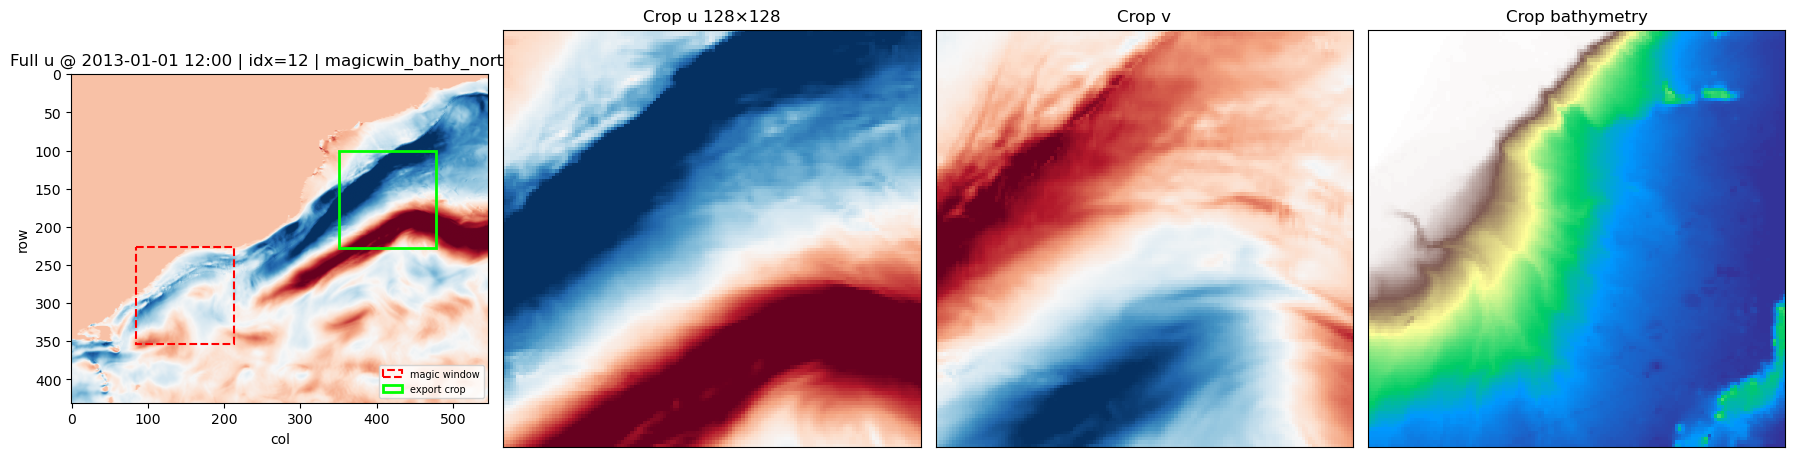

mask invalid fraction (crop): 0.0000
crop center lat/lon: [3.4778623580932617, -46.4599609375]


In [6]:
PREVIEW_IDX = int(candidate_idx[0]) if len(candidate_idx) else 0

seq_full, mask_full, times, _ = load_full_sequence(dataset_full, PREVIEW_IDX)
seq_crop, mask_crop, _, y_crop = load_sequence(dataset, PREVIEW_IDX, channel_names=CHANNEL_NAMES)

t0 = str(times[0])[:16]
field_u = seq_full[0, 0]
field_v = seq_crop[0, 1]
from src.export.fix_window_export import _bathymetry_field_2d

field_bathy = _bathymetry_field_2d(y_crop["bat"].detach().cpu().numpy())
vmin_u, vmax_u = np.nanpercentile(field_u, 2), np.nanpercentile(field_u, 98)
vmin_v, vmax_v = np.nanpercentile(field_v, 2), np.nanpercentile(field_v, 98)
vmin_b, vmax_b = np.nanpercentile(field_bathy[np.isfinite(field_bathy)], 2), np.nanpercentile(
    field_bathy[np.isfinite(field_bathy)], 98
)

fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

ax = axes[0]
ax.imshow(field_u, cmap="RdBu_r", vmin=vmin_u, vmax=vmax_u)
# Magic export window (reference)
ax.add_patch(
    Rectangle(
        (MAGIC_ANCHOR_LEFT, MAGIC_ANCHOR_TOP),
        MAGIC_WIDTH,
        MAGIC_HEIGHT,
        fill=False,
        edgecolor="red",
        linewidth=1.5,
        linestyle="--",
        label="magic window",
    )
)
# Active export crop
if float(WINDOW_ANGLE) == 0.0:
    ax.add_patch(
        Rectangle(
            (WINDOW_LEFT, WINDOW_TOP),
            CROP_WIDTH,
            CROP_HEIGHT,
            fill=False,
            edgecolor="lime",
            linewidth=2,
            label="export crop",
        )
    )
else:
    corners = rotated_window_corners(
        WINDOW_TOP, WINDOW_LEFT, CROP_HEIGHT, WINDOW_ANGLE, CROP_WIDTH
    )
    ax.add_patch(Polygon(corners, fill=False, edgecolor="lime", linewidth=2, label="export crop"))
    if ROTATION_PIVOT == "center" and PIVOT_COL is not None and PIVOT_ROW is not None:
        ax.plot(PIVOT_COL, PIVOT_ROW, "r*", ms=10, label="pivot (center)")
    elif ROTATION_PIVOT == "bottom_left" and PIVOT_COL is not None and PIVOT_ROW is not None:
        ax.plot(PIVOT_COL, PIVOT_ROW, "r*", ms=10, label="pivot (BL)")
ax.legend(loc="lower right", fontsize=7)
ax.set_title(f"Full u @ {t0} | idx={PREVIEW_IDX} | {EXPORT_KEY}")
ax.set_xlabel("col")
ax.set_ylabel("row")

ax = axes[1]
ax.imshow(seq_crop[0, 0], cmap="RdBu_r", vmin=vmin_u, vmax=vmax_u)
ax.set_title(f"Crop u {CROP_HEIGHT}×{CROP_WIDTH}")
ax.set_xticks([])
ax.set_yticks([])

ax = axes[2]
ax.imshow(field_v, cmap="RdBu_r", vmin=vmin_v, vmax=vmax_v)
ax.set_title("Crop v")
ax.set_xticks([])
ax.set_yticks([])

ax = axes[3]
ax.imshow(field_bathy, cmap="terrain_r", vmin=vmin_b, vmax=vmax_b)
ax.set_title("Crop bathymetry")
ax.set_xticks([])
ax.set_yticks([])

plt.tight_layout()
plt.show()

print(f"mask invalid fraction (crop): {float(mask_crop.mean()):.4f}")
print(f"crop center lat/lon: {y_crop['latlon'].tolist()}")
if EXPORT_KEY == "magic":
    print(f"magic .pt lat range: {mw_lat_range}")
    print(f"magic .pt lon range: {mw_lon_range}")


## Parallel export (resumable)

Runs in **chunks** on disk. Re-run the cell below to resume after interrupt.

- Progress: `{OUTPUT_PREFIX}_export_state.json`
- Chunk cache: `{OUTPUT_PREFIX}_chunks/`
- Set `DETACHED = True` for background export (recommended for large runs).

In [7]:
import importlib
import subprocess

import src.export.fix_window_export as _fwe
importlib.reload(_fwe)
from src.export.fix_window_export import ExportConfig, run_export

DETACHED = True
CHUNK_SIZE = 100
RESUME = True  # set False (or pass --no-resume) when channels/prefix changed, e.g. uv -> uvbathy

_EXPORT_ENV = {**os.environ, "CUDA_VISIBLE_DEVICES": ""}  # CPU-only background export


def _run_one_export(
    output_prefix: str,
    channel_names: tuple[str, ...],
    target_channel_indices: tuple[int, ...],
    *,
    start_time: str | None = None,
    end_time: str | None = None,
    n_samples_to_gen: int | None = None,
    fixed_dataset_indices: tuple[int, ...] | None = None,
):
    export_config = ExportConfig(
        zarr_path=ZARR_PATH,
        dt=DT,
        conditioning_steps=CONDITIONING_STEPS,
        forecast_steps=FORECAST_STEPS,
        crop_height=CROP_HEIGHT,
        crop_width=CROP_WIDTH,
        window_top=WINDOW_TOP,
        window_left=WINDOW_LEFT,
        window_angle=WINDOW_ANGLE,
        seed=SEED,
        n_jobs=N_JOBS,
        max_mask_frac=MAX_MASK_FRAC,
        hour_of_day=HOUR_OF_DAY,
        start_time=start_time or START_TIME,
        end_time=end_time or END_TIME,
        output_prefix=output_prefix,
        n_samples_to_gen=n_samples_to_gen if n_samples_to_gen is not None else N_SAMPLES_TO_GEN,
        chunk_size=CHUNK_SIZE,
        channel_names=channel_names,
        target_channel_indices=target_channel_indices,
        fixed_dataset_indices=fixed_dataset_indices,
    )

    config_path = Path(f"{output_prefix}_export_config.json")
    config_dict = asdict(export_config)
    config_dict["export_key"] = EXPORT_KEY
    config_dict["rotation_pivot"] = ROTATION_PIVOT
    config_dict["magic_pivot_bottom_left"] = [int(MAGIC_PIVOT_LEFT), int(MAGIC_PIVOT_BOTTOM_ROW)]
    config_dict["magic_anchor_top_left"] = [int(MAGIC_ANCHOR_TOP), int(MAGIC_ANCHOR_LEFT)]
    config_dict["magic_window_pt"] = str(MAGIC_PT_PATH.relative_to(MW_DIR))
    config_dict["magic_window_frac"] = magic_window_frac
    config_dict["row_slice"] = row_slice
    if col_slice is not None:
        config_dict["col_slice"] = col_slice
    config_path.write_text(json.dumps(config_dict, indent=2, default=str))
    print(f"Wrote config: {config_path}")

    if DETACHED:
        log_path = LOG_DIR / f"export_{EXPORT_KEY}_{Path(output_prefix).name}.log"
        cmd = [
            sys.executable,
            str(ROOT / "scripts/export_fix_window_data.py"),
            "--output-prefix",
            output_prefix,
        ]
        if not RESUME:
            cmd.append("--no-resume")
        with open(log_path, "a") as log_file:
            proc = subprocess.Popen(
                cmd,
                stdout=log_file,
                stderr=subprocess.STDOUT,
                start_new_session=True,
                cwd=ROOT,
                env=_EXPORT_ENV,
            )
        print(f"Started background export PID {proc.pid} -> {output_prefix}")
        print(f"Log: {log_path}")
        print(f"Monitor: tail -f {log_path}")
        print(
            f"Resume: python scripts/export_fix_window_data.py --output-prefix {output_prefix}"
        )
    else:
        run_export(export_config, resume=RESUME)


for component in EXPORT_COMPONENTS:
    train_prefix, ch_names, tgt_idx = _component_export_settings(
        component, TRAIN_DATA_PREFIX_BASE
    )
    val_prefix, _, _ = _component_export_settings(component, VAL_DATA_PREFIX_BASE)
    print(f"\n=== Train export: {component} -> {train_prefix} ({N_TRAIN} seq) ===")
    _run_one_export(
        train_prefix,
        ch_names,
        tgt_idx,
        n_samples_to_gen=N_TRAIN,
        fixed_dataset_indices=tuple(int(x) for x in train_zarr_idx),
    )
    print(f"\n=== Val export: {component} -> {val_prefix} ({N_VAL} seq) ===")
    _run_one_export(
        val_prefix,
        ch_names,
        tgt_idx,
        n_samples_to_gen=N_VAL,
        fixed_dataset_indices=tuple(int(x) for x in val_zarr_idx),
    )



=== Train export: uvbathy -> /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/data/magicwin_bathy_northeast/sample_13_22_train_uvbathy_dt360 (2880 seq) ===
Wrote config: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/data/magicwin_bathy_northeast/sample_13_22_train_uvbathy_dt360_export_config.json
Started background export PID 861752 -> /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/data/magicwin_bathy_northeast/sample_13_22_train_uvbathy_dt360
Log: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/logs/export_magicwin_bathy_northeast_sample_13_22_train_uvbathy_dt360.log
Monitor: tail -f /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/logs/export_magicwin_bathy_northeast_sample_13_22_train_uvbathy_dt360.log
Resume: python scripts/export_fix_window_data.py --output-prefix /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/data/magicwin_bathy_northeast/sample_13_22_train_uvbathy_dt360

=== Val export: uvbathy -> /opt/dl

## Optional — 2023 test export (rollout holdout)

Same window, **2023 only**. Saves to `Magic_window/data/{export_key}/sample_23_uvbathy_dt360_*`.


In [8]:
# 2023 test export — independent of train START_TIME / END_TIME above
# TEST_DATA_PREFIX_BASE set in cell 3
TEST_START_TIME = "2023-01-01"
TEST_END_TIME = "2023-12-31"
TEST_EXPORT_ALL = True
TEST_N_SAMPLES_TO_GEN = 999_999

test_kwargs = dict(
    path=ZARR_PATH,
    dt=DT,
    conditioning_steps=CONDITIONING_STEPS,
    forecast_steps=FORECAST_STEPS,
    start_time=TEST_START_TIME,
    end_time=TEST_END_TIME,
)
test_dataset = GuianaDataloader(**test_kwargs, transform=window_crop, device="cpu")
test_candidate_idx = candidate_indices_for_hour(test_dataset, HOUR_OF_DAY)
print(f"2023 test pool: {len(test_candidate_idx)} starts | HOUR_OF_DAY={HOUR_OF_DAY}")
test_n = len(test_candidate_idx) if TEST_EXPORT_ALL else min(TEST_N_SAMPLES_TO_GEN, len(test_candidate_idx))
print(f"Will export: {test_n} test sequences (export_all={TEST_EXPORT_ALL})")

for component in EXPORT_COMPONENTS:
    test_prefix, test_ch_names, test_tgt_idx = _component_export_settings(
        component, base=TEST_DATA_PREFIX_BASE
    )
    print(f"\n=== 2023 test export: {component} -> {test_prefix} ===")
    _run_one_export(
        test_prefix,
        test_ch_names,
        test_tgt_idx,
        start_time=TEST_START_TIME,
        end_time=TEST_END_TIME,
        n_samples_to_gen=test_n,
        fixed_dataset_indices=tuple(int(x) for x in test_candidate_idx) if TEST_EXPORT_ALL else None,
    )


2023 test pool: 319 starts | HOUR_OF_DAY=12
Will export: 319 test sequences (export_all=True)

=== 2023 test export: uvbathy -> /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/data/magicwin_bathy_northeast/sample_23_uvbathy_dt360 ===
Wrote config: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/data/magicwin_bathy_northeast/sample_23_uvbathy_dt360_export_config.json
Started background export PID 862029 -> /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/data/magicwin_bathy_northeast/sample_23_uvbathy_dt360
Log: /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/logs/export_magicwin_bathy_northeast_sample_23_uvbathy_dt360.log
Monitor: tail -f /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/logs/export_magicwin_bathy_northeast_sample_23_uvbathy_dt360.log
Resume: python scripts/export_fix_window_data.py --output-prefix /opt/dlami/nvme/tmp_storage/LCADAME/hamid_copy/Magic_window/data/magicwin_bathy_northeast/sample_23_uvbathy_dt360
